# 02 · Bernstein–Vazirani

Run: [setup](../SETUP.md). Qiskit ideal simulation; saved outputs are local. Run your version in qBraid Lab (or implement it in Classiq).

**Question:** which switches contribute to a diagnostic's warning bit? **Input:** a rule that XORs an unknown subset of input bits. XOR returns 1 when an odd number of the selected bits are 1. **Output:** a mask identifying the selected bits: `101` means use bits 2 and 0. This teaches learning a hidden rule under a strong assumption; it does not reverse-engineer arbitrary software.

1. Apply **H (Hadamard)** gates to give inputs equal amplitudes: signed weights whose squared magnitudes are probabilities. Prepare a helper qubit with equal but opposite-signed amplitudes.
2. Query the **oracle**, a reversible circuit that flips the helper when the rule returns 1. This changes the corresponding input amplitude's sign.
3. Apply H to the inputs again. **Interference** combines those signed amplitudes so the measured string is the mask.

Qiskit prints bits as `q2 q1 q0`, with qubit 0 on the right.

In [1]:
%matplotlib inline
import qiskit
import numpy as np
import matplotlib.pyplot as plt
from qiskit import QuantumCircuit
from qiskit.quantum_info import Statevector

print('Qiskit', qiskit.__version__)
SHOTS, SEED = 512, 2026

def bernstein_vazirani(mask):
    n = len(mask)
    circuit = QuantumCircuit(n + 1)
    circuit.x(n)
    circuit.h(range(n + 1))
    # Build a toy oracle: XOR the selected inputs into the helper.
    for qubit, bit in enumerate(reversed(mask)):
        if bit == '1':
            circuit.cx(qubit, n)
    circuit.h(range(n))
    return circuit

def classical_recovery(mask):
    # Each ordinary query turns on one input bit and reveals one mask bit.
    def flag(x):
        return (x & int(mask, 2)).bit_count() % 2
    answers = [flag(1 << q) for q in range(len(mask))]
    return ''.join(str(bit) for bit in reversed(answers))

Qiskit 2.3.0


**Predict:** how will changing the mask from `101` to `011` change the result? One shot samples one simulated measurement. The circuit builder knows the mask; the algorithm uses its resulting oracle without inspecting the mask variable.

Mask 101: measured 101 | classical check passed
Mask 011: measured 011 | classical check passed


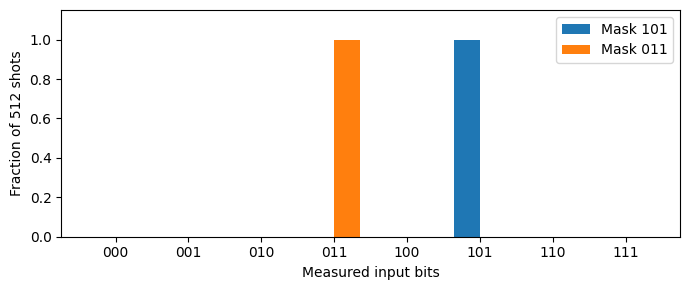

In [2]:
masks = ['101', '011']
labels = [format(x, '03b') for x in range(8)]
frequencies = {}
for mask in masks:
    state = Statevector.from_instruction(bernstein_vazirani(mask))
    state.seed(SEED)
    probabilities = state.probabilities(qargs=[0, 1, 2])
    counts = state.sample_counts(SHOTS, qargs=[0, 1, 2])
    assert np.isclose(probabilities[int(mask, 2)], 1)
    assert classical_recovery(mask) == max(counts, key=counts.get) == mask
    frequencies[mask] = [counts.get(label, 0) / SHOTS for label in labels]
    print(f"Mask {mask}: measured {max(counts, key=counts.get)} | classical check passed")

x = np.arange(8)
fig, ax = plt.subplots(figsize=(7, 3))
ax.bar(x - .18, frequencies['101'], .36, label='Mask 101')
ax.bar(x + .18, frequencies['011'], .36, label='Mask 011')
ax.set(xticks=x, xticklabels=labels, xlabel='Measured input bits',
       ylabel=f'Fraction of {SHOTS} shots', ylim=(0, 1.15))
ax.legend()
plt.tight_layout()
plt.show()

An ideal run recovers an $n$-bit mask in one coherent oracle query; classical one-bit queries require $n$ for certain recovery. This assumes quantum access to the function, not an ordinary API. Building the oracle, executing gates, and repeating shots cost resources. Here the mask is visible in code, so the simulation demonstrates no practical speedup.

**Try:** remove the final H layer, predict the distribution, and replace the deterministic-output assertions with a uniform-probability check.

[IBM explanation, including Bernstein-Vazirani](https://quantum.cloud.ibm.com/learning/en/courses/fundamentals-of-quantum-algorithms/quantum-query-algorithms/deutsch-jozsa-algorithm).